In [7]:
import numpy as np
from dataclasses import dataclass
from typing import List, Tuple, Optional

@dataclass
class RobotParameters:
    """
    Physical and electrical parameters for the 4-omniwheel robot simulation.
    """
    # Chassis Physical Parameters
    mass: float = 2.7               # Robot mass in kg
    inertia: float = 0.0074         # Rotational inertia Izz in kg*m^2 (7400 kg*mm^2)
    R_base: float = 0.06            # Wheel base contact radius from center in m (60 mm)
    
    # Derived half-dimensions for symmetric placement along base circle
    @property
    def Lx(self) -> float:
        return self.R_base / np.sqrt(2)
    @property
    def Ly(self) -> float:
        return self.R_base / np.sqrt(2)

    # Wheel & Roller Geometry
    R: float = 0.03                 # Wheel radius in m (30 mm)
    alpha_f: float = np.radians(30) # Front wheel mounting angle (30 deg)
    alpha_b: float = np.radians(45) # Back wheel mounting angle (45 deg)

    # DC Motor Parameters (Torque-speed limit & power model)
    tau_stall: float = 2.0          # Motor stall torque in N*m
    omega_max: float = 150.0        # Motor max free speed in rad/s
    Kt: float = 0.1                 # Motor torque constant in N*m/A
    Kv: float = 1.0                 # Motor velocity constant

    # Friction & Ground Parameters
    mu_s: float = 0.8               # Static friction coefficient
    mu_k: float = 0.5               # Kinetic/dynamic friction coefficient
    g: float = 9.81                 # Gravitational acceleration in m/s^2

    # Disturbance / Inaccuracy Flags & Parameters
    enable_disturbances: bool = False
    pose_noise_std: float = 0.001   # Standard deviation for pose process noise
    friction_noise_std: float = 0.05# Standard deviation for friction coefficient noise


@dataclass
class RobotState:
    """
    Represents the full system state vector x_k at any time step k.
    """
    pose: np.ndarray                # Global [X, Y, theta] in meters and radians
    velocity: np.ndarray            # Body-frame [vx, vy, omega] in m/s and rad/s
    wheel_velocities: np.ndarray    # Actual per-wheel angular velocities [omega_1, ..., omega_4] in rad/s
    motor_torques: np.ndarray       # Applied motor torques [tau_1, ..., tau_4] in N*m
    ground_forces: np.ndarray       # Contact forces per wheel shape (4, 3) -> [Fx, Fy, Fz] per wheel


class OmniWheelSimulation:
    """
    Discrete-time simulation engine for a 4-omniwheel mobile robot.
    Handles kinematics, DC motor power limits, Coulomb friction/slip transitions,
    and trajectory cost computation.
    """
    def __init__(self, params: RobotParameters, initial_state: Optional[RobotState] = None):
        self.params = params
        
        if initial_state is not None:
            self.state = initial_state
        else:
            # Default initial state at origin with zero velocities
            self.state = RobotState(
                pose=np.zeros(3),
                velocity=np.zeros(3),
                wheel_velocities=np.zeros(4),
                motor_torques=np.zeros(4),
                ground_forces=np.zeros((4, 3))
            )

    def get_wheel_orientation_vectors(self) -> np.ndarray:
        """
        Computes the unit vector pointing in the active rolling direction (u_hat) 
        for each of the 4 wheels in the robot body frame, accounting for asymmetric 
        front (alpha_f) and back (alpha_b) mounting angles.
        
        Returns:
            np.ndarray: Shape (4, 2) containing body-frame unit vectors for wheels 1 to 4.
        """
        af = self.params.alpha_f
        ab = self.params.alpha_b
        
        # Wheel 1: Front-Left (alpha_f)
        u1 = np.array([np.cos(af), np.sin(af)])
        # Wheel 2: Front-Right (-alpha_f, symmetric across centerline)
        u2 = np.array([np.cos(-af), np.sin(-af)])
        # Wheel 3: Rear-Right (180 - alpha_b)
        u3 = np.array([np.cos(np.pi - ab), np.sin(np.pi - ab)])
        # Wheel 4: Rear-Left (180 + alpha_b)
        u4 = np.array([np.cos(np.pi + ab), np.sin(np.pi + ab)])
        
        return np.vstack([u1, u2, u3, u4])

    def get_wheel_positions(self) -> np.ndarray:
        """
        Defines position vectors from robot center of mass (CoM) to each wheel hub.
        
        Returns:
            np.ndarray: Shape (4, 2) representing [x_i, y_i] for each wheel 1..4.
        """
        Lx = self.params.Lx
        Ly = self.params.Ly
        
        r1 = np.array([Lx, Ly])   # Front-Left
        r2 = np.array([Lx, -Ly])  # Front-Right
        r3 = np.array([-Lx, -Ly]) # Rear-Right
        r4 = np.array([-Lx, Ly])  # Rear-Left
        
        return np.vstack([r1, r2, r3, r4])

    def step(self, u_wheel_speeds: np.ndarray, dt: float) -> Tuple[RobotState, float]:
        """
        Executes a single discrete-time simulation step (k -> k+1).
        
        Args:
            u_wheel_speeds (np.ndarray): Desired per-wheel angular velocities [omega_1, ..., omega_4] (rad/s).
            dt (float): Time step duration in seconds.
            
        Returns:
            Tuple[RobotState, float]: The updated RobotState object and the step cost (power + penalties).
        """
        p = self.params
        
        # ---------------------------------------------------------------------
        # 1. Disturbance Injection (if enabled)
        # ---------------------------------------------------------------------
        mu_s = p.mu_s
        mu_k = p.mu_k
        if p.enable_disturbances:
            # Add random variation to friction coefficients per wheel
            mu_s_vec = np.clip(mu_s + np.random.normal(0, p.friction_noise_std, 4), 0.1, 2.0)
            mu_k_vec = np.clip(mu_k + np.random.normal(0, p.friction_noise_std, 4), 0.05, 1.5)
        else:
            mu_s_vec = np.full(4, mu_s)
            mu_k_vec = np.full(4, mu_k)

        # ---------------------------------------------------------------------
        # 2. DC Motor Torque-Speed Limit & Power Calculation
        # ---------------------------------------------------------------------
        current_omega = self.state.wheel_velocities
        tau_limits = p.tau_stall * np.maximum(0.0, 1.0 - np.abs(current_omega) / p.omega_max)
        
        raw_torques = p.Kt * (u_wheel_speeds - current_omega)
        motor_torques = np.clip(raw_torques, -tau_limits, tau_limits)
        
        motor_currents = np.abs(motor_torques) / p.Kt
        electrical_power_per_wheel = motor_currents * 12.0 # assuming 12V nominal bus voltage
        total_electrical_power = np.sum(electrical_power_per_wheel)

        # ---------------------------------------------------------------------
        # 3. Ground Reaction Forces & Coulomb Friction / Slip Check
        # ---------------------------------------------------------------------
        Fz_per_wheel = (p.mass * p.g) / 4.0
        
        ground_forces = np.zeros((4, 3))
        effective_wheel_forces = np.zeros(4)
        
        for i in range(4):
            fz = Fz_per_wheel
            ground_forces[i, 2] = fz
            
            f_drive = motor_torques[i] / p.R
            f_max_static = mu_s_vec[i] * fz
            
            if np.abs(f_drive) <= f_max_static:
                effective_wheel_forces[i] = f_drive
            else:
                effective_wheel_forces[i] = mu_k_vec[i] * fz * np.sign(f_drive)
                
            u_i = self.get_wheel_orientation_vectors()[i]
            fx_i = effective_wheel_forces[i] * u_i[0]
            fy_i = effective_wheel_forces[i] * u_i[1]
            ground_forces[i, 0] = fx_i
            ground_forces[i, 1] = fy_i

        # ---------------------------------------------------------------------
        # 4. Rigid-Body Mechanics (Net Force & Torque -> Body Acceleration)
        # ---------------------------------------------------------------------
        r_vectors = self.get_wheel_positions()
        u_vectors = self.get_wheel_orientation_vectors()
        
        F_net_body = np.zeros(2)
        tau_net_z = 0.0
        
        for i in range(4):
            F_i_vec = effective_wheel_forces[i] * u_vectors[i]
            F_net_body += F_i_vec
            tau_net_z += r_vectors[i, 0] * F_i_vec[1] - r_vectors[i, 1] * F_i_vec[0]
            
        ax_body = F_net_body[0] / p.mass
        ay_body = F_net_body[1] / p.mass
        alpha_body = tau_net_z / p.inertia
        
        # ---------------------------------------------------------------------
        # 5. Numerical Integration (Euler Integration for State Propagation)
        # ---------------------------------------------------------------------
        vx_prev, vy_prev, omega_prev = self.state.velocity
        
        vx_next = vx_prev + ax_body * dt
        vy_next = vy_prev + ay_body * dt
        omega_next = omega_prev + alpha_body * dt
        body_velocity_next = np.array([vx_next, vy_next, omega_next])
        
        theta_prev = self.state.pose[2]
        R_rot = np.array([
            [np.cos(theta_prev), -np.sin(theta_prev), 0],
            [np.sin(theta_prev),  np.cos(theta_prev), 0],
            [0,                   0,                  1]
        ])
        v_global = R_rot @ np.array([vx_next, vy_next, omega_next])
        
        pose_next = self.state.pose + v_global * dt
        
        if p.enable_disturbances:
            pose_next += np.random.normal(0, p.pose_noise_std, 3)

        wheel_velocities_next = current_omega + (u_wheel_speeds - current_omega) * min(1.0, dt * 20.0)

        next_state = RobotState(
            pose=pose_next,
            velocity=body_velocity_next,
            wheel_velocities=wheel_velocities_next,
            motor_torques=motor_torques,
            ground_forces=ground_forces
        )
        
        # ---------------------------------------------------------------------
        # 6. Step Cost Calculation
        # ---------------------------------------------------------------------
        slip_penalty = np.sum(np.abs(f_drive - effective_wheel_forces)) * 10.0
        step_cost = total_electrical_power * dt + slip_penalty * dt

        self.state = next_state
        return next_state, step_cost

    def run_simulation(self, control_trajectory: np.ndarray, dt: float) -> Tuple[List[RobotState], float]:
        trajectory_states = [self.state]
        total_cost = 0.0
        
        for u_speeds in control_trajectory:
            next_st, cost = self.step(u_speeds, dt)
            trajectory_states.append(next_st)
            total_cost += cost
            
        return trajectory_states, total_cost

Initializing Robot Parameters...
Running Scenario 1: Pure Forward Motion...
 -> Clean Cost: 210.51 | Disturbed Cost: 211.51


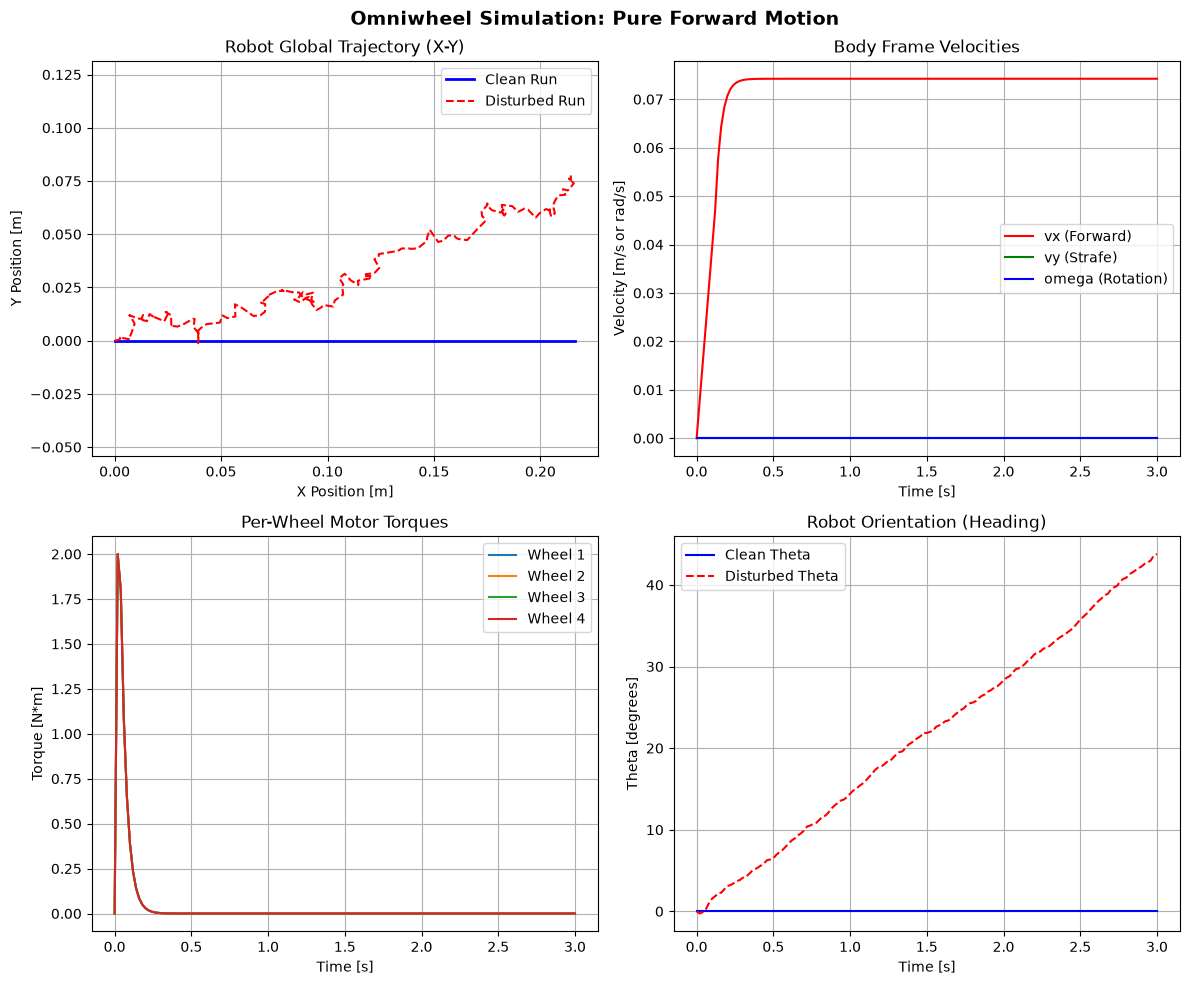

Running Scenario 2: Pure Sideways Strafe...
 -> Clean Cost: 208.53 | Disturbed Cost: 208.29


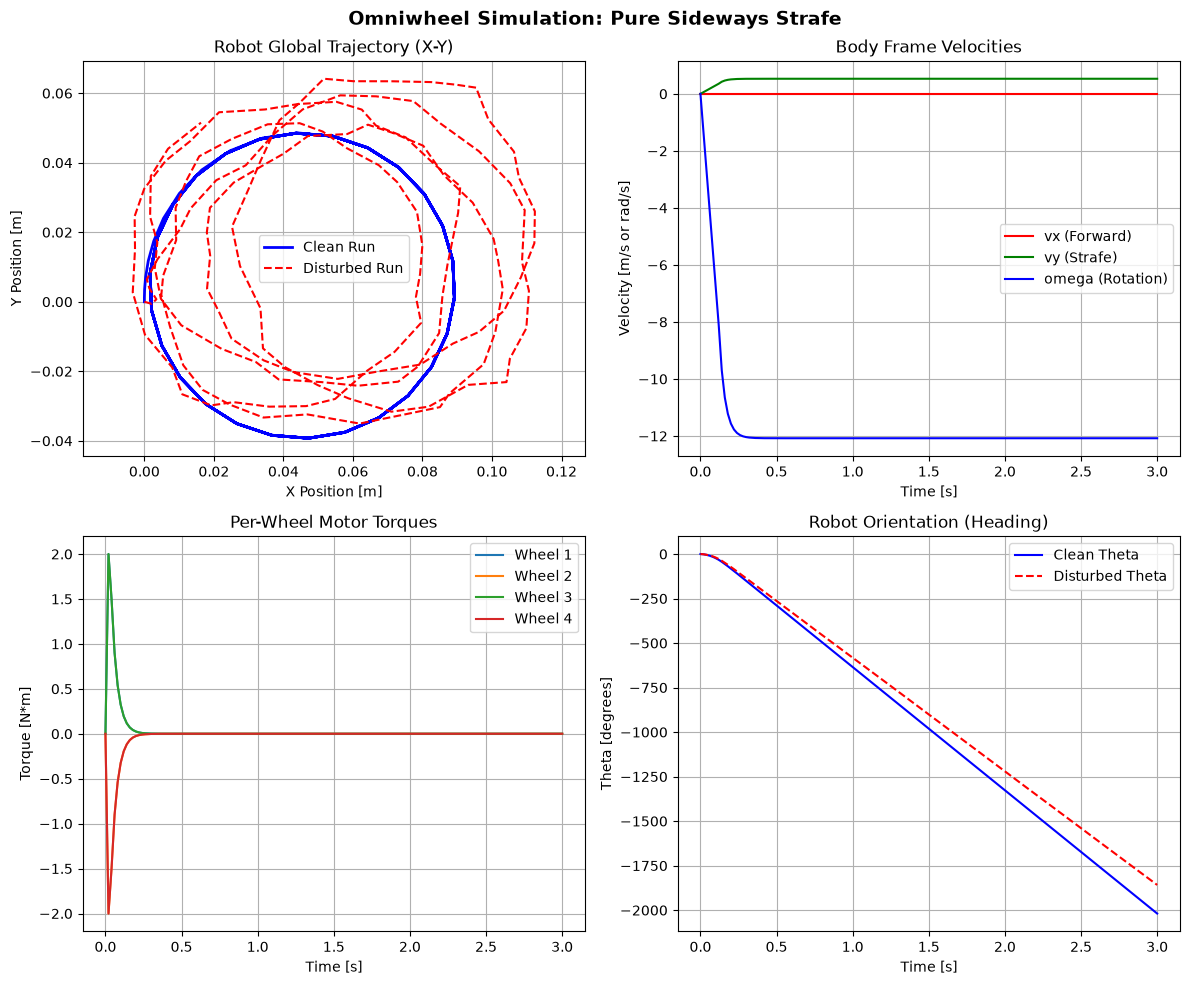

Running Scenario 3: Pure Rotation in Place...
 -> Clean Cost: 181.33 | Disturbed Cost: 180.91


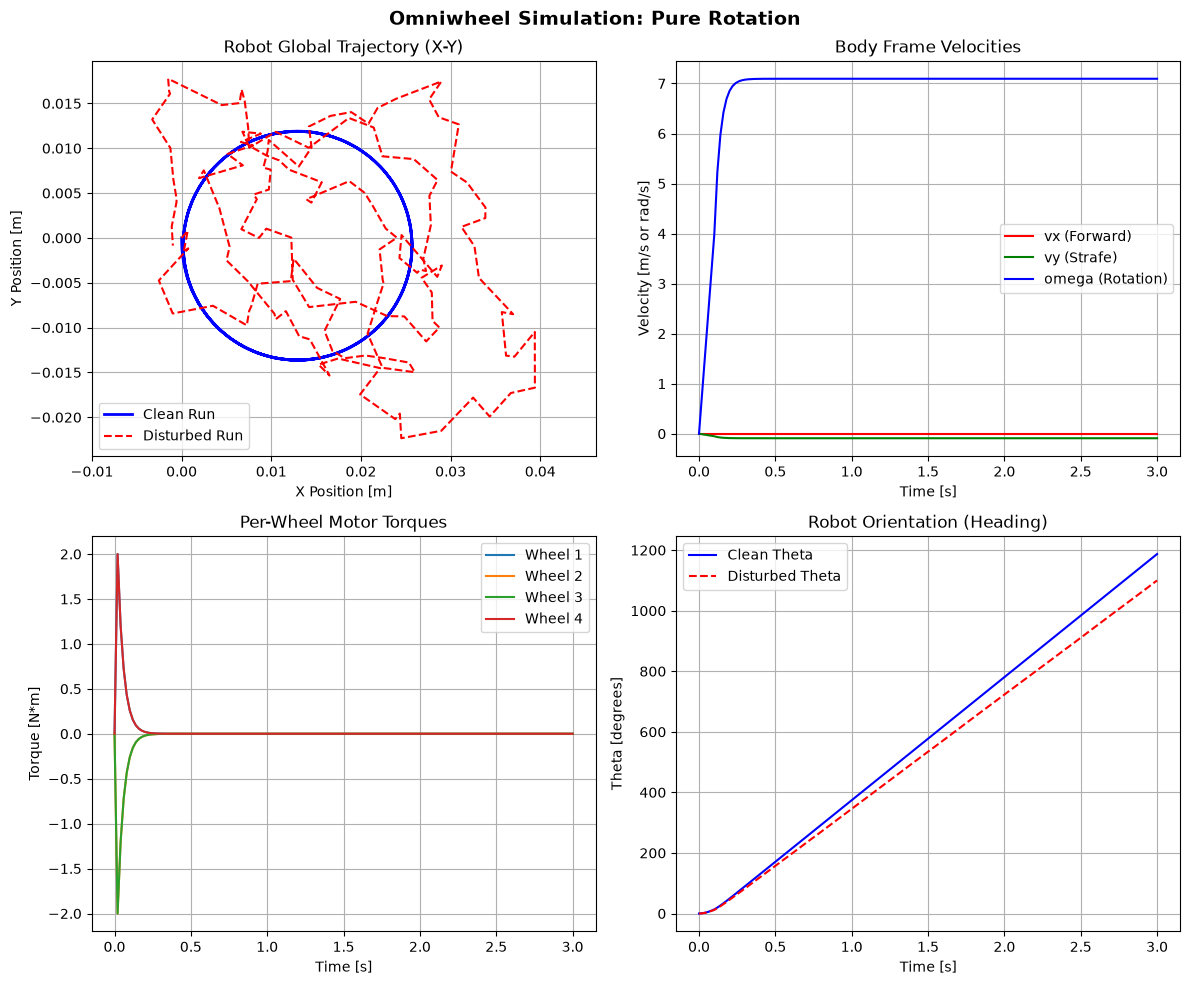

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from typing import List
#from omniwheel_simulator import RobotParameters, OmniWheelSimulation, RobotState

class OmniWheelPlotter:
    """
    Interactive plotting class for visualizing robot trajectories, body velocities,
    motor torques, and power consumption across different motion maneuvers.
    """
    def __init__(self):
        plt.ion() # Turn on interactive mode for live display if desired

    def plot_comparison(self, title_prefix: str, 
                        clean_states: List[RobotState], 
                        disturbed_states: List[RobotState], 
                        dt: float):
        """
        Generates a 4-panel comparison plot between clean and disturbed simulation runs.
        """
        time_clean = np.arange(len(clean_states)) * dt
        time_dist = np.arange(len(disturbed_states)) * dt

        # Extract trajectories (X, Y)
        xy_clean = np.array([s.pose[:2] for s in clean_states])
        xy_dist = np.array([s.pose[:2] for s in disturbed_states])

        # Extract body velocities [vx, vy, omega]
        vel_clean = np.array([s.velocity for s in clean_states])
        
        # Extract motor torques [tau_1, tau_2, tau_3, tau_4]
        torques_clean = np.array([s.motor_torques for s in clean_states])

        fig, axs = plt.subplots(2, 2, figsize=(12, 10))
        fig.suptitle(f"Omniwheel Simulation: {title_prefix}", fontsize=14, fontweight='bold')

        # 1. Trajectory (X vs Y)
        axs[0, 0].plot(xy_clean[:, 0], xy_clean[:, 1], 'b-', linewidth=2, label='Clean Run')
        axs[0, 0].plot(xy_dist[:, 0], xy_dist[:, 1], 'r--', linewidth=1.5, label='Disturbed Run')
        axs[0, 0].set_title("Robot Global Trajectory (X-Y)")
        axs[0, 0].set_xlabel("X Position [m]")
        axs[0, 0].set_ylabel("Y Position [m]")
        axs[0, 0].grid(True)
        axs[0, 0].legend()
        axs[0, 0].axis('equal')

        # 2. Body Velocities over time
        axs[0, 1].plot(time_clean, vel_clean[:, 0], 'r-', label='vx (Forward)')
        axs[0, 1].plot(time_clean, vel_clean[:, 1], 'g-', label='vy (Strafe)')
        axs[0, 1].plot(time_clean, vel_clean[:, 2], 'b-', label='omega (Rotation)')
        axs[0, 1].set_title("Body Frame Velocities")
        axs[0, 1].set_xlabel("Time [s]")
        axs[0, 1].set_ylabel("Velocity [m/s or rad/s]")
        axs[0, 1].grid(True)
        axs[0, 1].legend()

        # 3. Per-wheel Motor Torques (Clean run)
        for i in range(4):
            axs[1, 0].plot(time_clean, torques_clean[:, i], label=f'Wheel {i+1}')
        axs[1, 0].set_title("Per-Wheel Motor Torques")
        axs[1, 0].set_xlabel("Time [s]")
        axs[1, 0].set_ylabel("Torque [N*m]")
        axs[1, 0].grid(True)
        axs[1, 0].legend()

        # 4. Heading Angle (theta) over time
        theta_clean = np.array([s.pose[2] for s in clean_states])
        theta_dist = np.array([s.pose[2] for s in disturbed_states])
        axs[1, 1].plot(time_clean, np.degrees(theta_clean), 'b-', label='Clean Theta')
        axs[1, 1].plot(time_dist, np.degrees(theta_dist), 'r--', label='Disturbed Theta')
        axs[1, 1].set_title("Robot Orientation (Heading)")
        axs[1, 1].set_xlabel("Time [s]")
        axs[1, 1].set_ylabel("Theta [degrees]")
        axs[1, 1].grid(True)
        axs[1, 1].legend()

        plt.tight_layout()
        plt.show()


def run_test_scenarios():
    dt = 0.02 # 50 Hz simulation step
    sim_duration = 3.0 # seconds
    num_steps = int(sim_duration / dt)

    print("Initializing Robot Parameters...")
    params = RobotParameters(
        mass=2.7,
        inertia=0.0074,
        R_base=0.06,
        R=0.03,
        alpha_f=np.radians(30),
        alpha_b=np.radians(45),
        enable_disturbances=False
    )

    plotter = OmniWheelPlotter()

    # =========================================================================
    # Scenario 1: Pure Forward Motion
    # =========================================================================
    print("Running Scenario 1: Pure Forward Motion...")
    # Desired wheel speeds for forward motion [rad/s]
    forward_speed = 30.0
    control_traj_fwd = np.tile([forward_speed, forward_speed, forward_speed, forward_speed], (num_steps, 1))

    # Clean Simulation
    sim_clean = OmniWheelSimulation(params)
    states_clean, cost_clean = sim_clean.run_simulation(control_traj_fwd, dt)

    # Disturbed Simulation
    params_dist = RobotParameters(enable_disturbances=True, pose_noise_std=0.002, friction_noise_std=0.1)
    sim_dist = OmniWheelSimulation(params_dist)
    states_dist, cost_dist = sim_dist.run_simulation(control_traj_fwd, dt)

    print(f" -> Clean Cost: {cost_clean:.2f} | Disturbed Cost: {cost_dist:.2f}")
    plotter.plot_comparison("Pure Forward Motion", states_clean, states_dist, dt)

    # =========================================================================
    # Scenario 2: Pure Sideways Strafe
    # =========================================================================
    print("Running Scenario 2: Pure Sideways Strafe...")
    # Omniwheel combination for lateral motion
    strafe_speeds = np.array([25.0, -25.0, 25.0, -25.0])
    control_traj_strafe = np.tile(strafe_speeds, (num_steps, 1))

    sim_clean = OmniWheelSimulation(params)
    states_clean, cost_clean = sim_clean.run_simulation(control_traj_strafe, dt)

    sim_dist = OmniWheelSimulation(params_dist)
    states_dist, cost_dist = sim_dist.run_simulation(control_traj_strafe, dt)

    print(f" -> Clean Cost: {cost_clean:.2f} | Disturbed Cost: {cost_dist:.2f}")
    plotter.plot_comparison("Pure Sideways Strafe", states_clean, states_dist, dt)

    # =========================================================================
    # Scenario 3: Pure Rotation in Place
    # =========================================================================
    print("Running Scenario 3: Pure Rotation in Place...")
    # Rotate wheels in opposite pairs
    rotate_speeds = np.array([20.0, -20.0, -20.0, 20.0])
    control_traj_rot = np.tile(rotate_speeds, (num_steps, 1))

    sim_clean = OmniWheelSimulation(params)
    states_clean, cost_clean = sim_clean.run_simulation(control_traj_rot, dt)

    sim_dist = OmniWheelSimulation(params_dist)
    states_dist, cost_dist = sim_dist.run_simulation(control_traj_rot, dt)

    print(f" -> Clean Cost: {cost_clean:.2f} | Disturbed Cost: {cost_dist:.2f}")
    plotter.plot_comparison("Pure Rotation", states_clean, states_dist, dt)



run_test_scenarios()

In [9]:
import numpy as np
from typing import Tuple

class PIDController:
    """
    Multi-axis PID controller for tracking translational and rotational body velocities
    based on pose errors. Includes integral anti-windup and output saturation.
    """
    def __init__(self, kp: np.ndarray, ki: np.ndarray, kd: np.ndarray, output_limits: np.ndarray):
        self.kp = np.array(kp, dtype=float)                 # [Kp_x, Kp_y, Kp_theta]
        self.ki = np.array(ki, dtype=float)                 # [Ki_x, Ki_y, Ki_theta]
        self.kd = np.array(kd, dtype=float)                 # [Kd_x, Kd_y, Kd_theta]
        self.output_limits = np.array(output_limits, dtype=float) # Max absolute velocity limits [vx, vy, omega]
        
        self.integral_error = np.zeros(3)
        self.previous_error = np.zeros(3)

    def reset(self):
        """Resets integral and derivative error states."""
        self.integral_error = np.zeros(3)
        self.previous_error = np.zeros(3)

    def compute(self, target_pose: np.ndarray, current_pose: np.ndarray, dt: float) -> np.ndarray:
        """
        Computes body-frame velocity commands [vx, vy, omega] given target and current global poses.
        """
        # 1. Calculate global pose error [dx, dy, dtheta]
        dx = target_pose[0] - current_pose[0]
        dy = target_pose[1] - current_pose[1]
        
        # Normalize heading error to [-pi, pi]
        dtheta = target_pose[2] - current_pose[2]
        dtheta = np.arctan2(np.sin(dtheta), np.cos(dtheta))
        
        error_global = np.array([dx, dy, dtheta])

        # 2. Transform global position error into robot body frame
        theta_current = current_pose[2]
        cos_t = np.cos(theta_current)
        sin_t = np.sin(theta_current)
        
        ex_body =  cos_t * error_global[0] + sin_t * error_global[1]
        ey_body = -sin_t * error_global[0] + cos_t * error_global[1]
        etheta  = error_global[2]
        
        error_body = np.array([ex_body, ey_body, etheta])

        # 3. PID Terms Calculation
        p_term = self.kp * error_body
        
        # Integral term with anti-windup clamping
        self.integral_error += error_body * dt
        self.integral_error = np.clip(self.integral_error, -1.5, 1.5)
        i_term = self.ki * self.integral_error
        
        # Derivative term
        if dt > 0:
            d_term = self.kd * (error_body - self.previous_error) / dt
        else:
            d_term = np.zeros(3)
            
        self.previous_error = error_body

        # 4. Total command with output saturation limits
        raw_output = p_term + i_term + d_term
        body_vel_cmd = np.clip(raw_output, -self.output_limits, self.output_limits)

        return body_vel_cmd


class Figure8PathGenerator:
    """
    Generates reference poses and feedforward velocities along a parametric Figure-8 (Lemniscate) curve.
    """
    def __init__(self, amplitude: float = 1.0, period: float = 12.0):
        self.A = amplitude       # Scale/size of the figure 8 path
        self.T = period          # Time period to complete one full loop
        self.omega_p = 2.0 * np.pi / self.T

    def get_reference_pose(self, t: float) -> np.ndarray:
        """
        Returns reference pose [X_ref, Y_ref, theta_ref] at time t.
        """
        w = self.omega_p
        A = self.A
        
        # Parametric Position Equations (Lemniscate)
        x_ref = A * np.sin(w * t)
        y_ref = (A / 2.0) * np.sin(2.0 * w * t)
        
        # Analytical velocities for heading alignment (dx/dt, dy/dt)
        vx_ref = A * w * np.cos(w * t)
        vy_ref = A * w * (2.0) * np.cos(2.0 * w * t)
        
        # Path-aligned heading theta
        theta_ref = np.arctan2(vy_ref, vx_ref)
        
        return np.array([x_ref, y_ref, theta_ref])


def compute_inverse_kinematics(body_velocities: np.ndarray, R_base: float, R: float, alpha_f: float, alpha_b: float) -> np.ndarray:
    """
    Linear inverse kinematic mapping translating body velocity [vx, vy, omega] 
    to per-wheel angular velocities [omega_1, omega_2, omega_3, omega_4].
    
    Args:
        body_velocities (np.ndarray): [vx, vy, omega] in m/s and rad/s.
        R_base (float): Wheel contact radius from center.
        R (float): Wheel radius.
        alpha_f, alpha_b (float): Front and back wheel mounting angles.
    """
    vx, vy, omega = body_velocities
    
    # Each wheel's speed contribution is derived from body velocities projected onto wheel heading
    # u_i = [cos(alpha_i), sin(alpha_i)] and rolling constraint accounting for rotation omega * R_base
    af = alpha_f
    ab = alpha_b
    
    # Wheel geometry mapping factors
    w1 = (1.0 / R) * (vx * np.cos(af) + vy * np.sin(af) + R_base * omega)
    w2 = (1.0 / R) * (vx * np.cos(-af) + vy * np.sin(-af) + R_base * omega)
    w3 = (1.0 / R) * (vx * np.cos(np.pi - ab) + vy * np.sin(np.pi - ab) + R_base * omega)
    w4 = (1.0 / R) * (vx * np.cos(np.pi + ab) + vy * np.sin(np.pi + ab) + R_base * omega)
    
    return np.array([w1, w2, w3, w4])

Executing Figure-8 Path Tracking (Clean Simulation)...
Executing Figure-8 Path Tracking (Disturbed Simulation)...


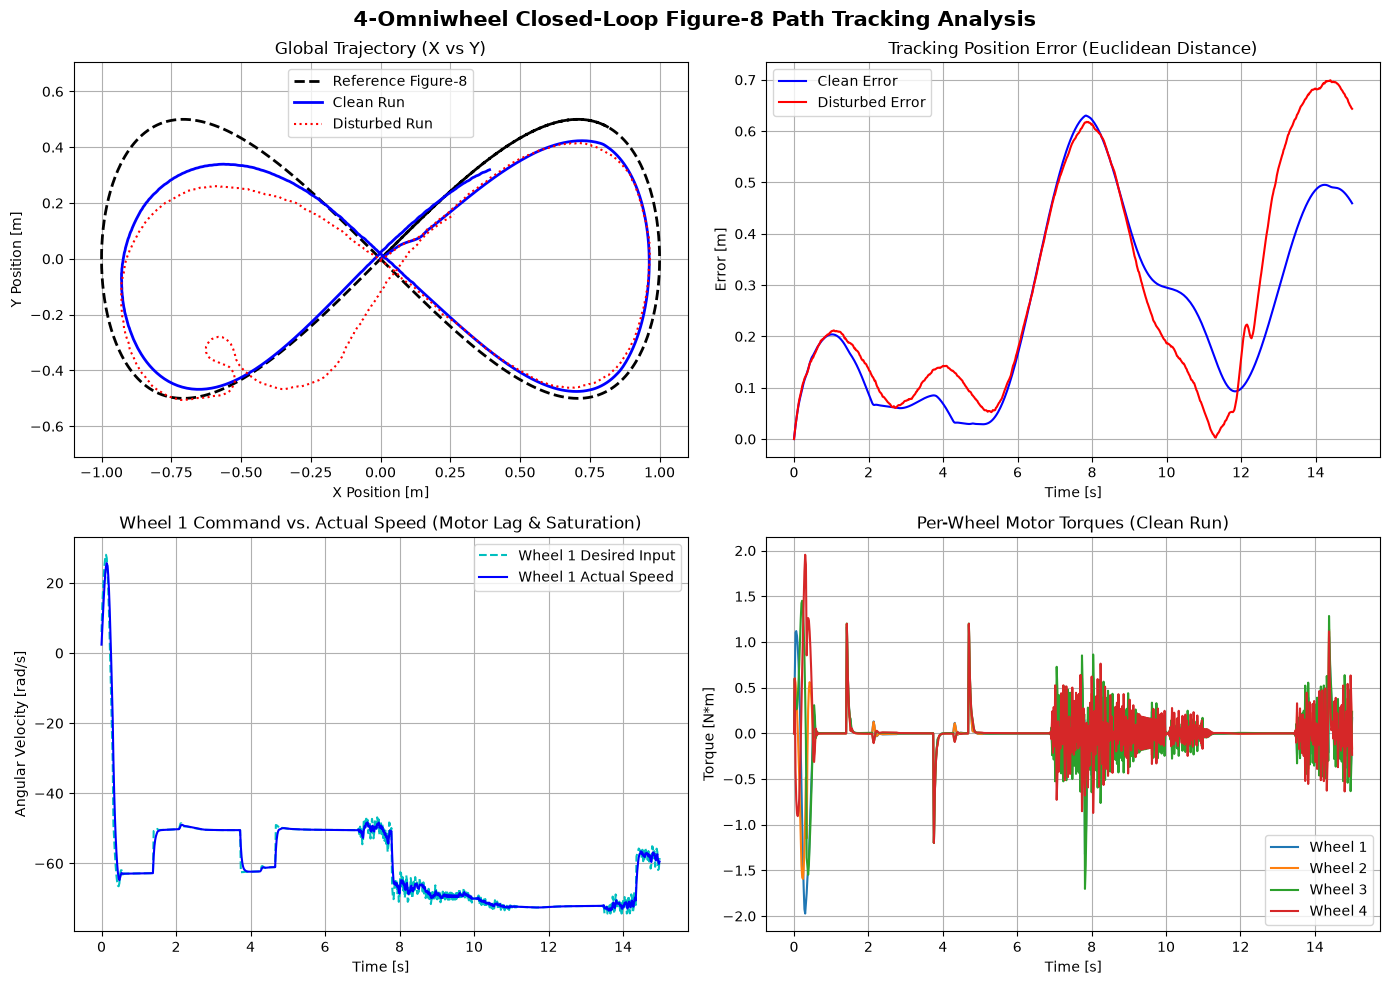

Path tracking simulation and plotting completed successfully!


In [34]:
import numpy as np
import matplotlib.pyplot as plt
#from omniwheel_simulator import RobotParameters, OmniWheelSimulation
#from ControlSetup import PIDController, Figure8PathGenerator, compute_inverse_kinematics

def run_path_tracking_simulation():
    """
    Executes a closed-loop path tracking simulation for a 4-omniwheel robot
    following a parametric Figure-8 (Lemniscate) trajectory. Compares nominal (clean) 
    performance against disturbed conditions (friction noise, pose drift, and motor saturation).
    """
    # -------------------------------------------------------------------------
    # 1. Simulation & Control Setup
    # -------------------------------------------------------------------------
    dt = 0.02                    # 50 Hz control and simulation loop timestep (20ms)
    total_time = 15.0            # Total duration covering more than one full Figure-8 loop
    num_steps = int(total_time / dt)

    # Clean physics parameters (ideal mechanics)
    params_clean = RobotParameters(
        mass=2.7,
        inertia=0.0074,
        R_base=0.06,
        R=0.03,
        alpha_f=np.radians(30),
        alpha_b=np.radians(45),
        enable_disturbances=False
    )

    # Disturbed physics parameters (adds friction variations and pose noise)
    params_disturbed = RobotParameters(
        mass=2.7,
        inertia=0.0074,
        R_base=0.06,
        R=0.03,
        alpha_f=np.radians(30),
        alpha_b=np.radians(45),
        enable_disturbances=True,
        pose_noise_std=0.001,
        friction_noise_std=0.08
    )

    # PID Controller Gains for [X position, Y position, Heading Theta]
    kp = [12.0, 12.0, 4.0]
    ki = [3.0, 3.0, 0.5]
    kd = [0.1, 0.1, 0.1]
    output_limits = [1.5, 1.5, 3.0] # Maximum absolute body velocity limits [vx, vy, omega]

    # Initialize Path Generator (Figure-8 Lemniscate curve)
    path_gen = Figure8PathGenerator(amplitude=1.0, period=13.0)

    # =========================================================================
    # 2. Run Simulation: Clean Condition
    # =========================================================================
    print("Executing Figure-8 Path Tracking (Clean Simulation)...")
    sim_clean = OmniWheelSimulation(params_clean)
    controller_clean = PIDController(kp, ki, kd, output_limits)
    
    clean_states = [sim_clean.state]
    reference_poses = []
    desired_wheel_inputs_clean = []
    actual_wheel_speeds_clean = []

    for k in range(num_steps):
        t = k * dt
        # Get reference pose from path generator
        ref_pose = path_gen.get_reference_pose(t)
        reference_poses.append(ref_pose)
        
        current_pose = sim_clean.state.pose
        
        # Step A: PID controller computes required body-frame velocities [vx, vy, omega]
        body_vel_cmd = controller_clean.compute(ref_pose, current_pose, dt)
        
        # Step B: Inverse kinematics maps body velocities to per-wheel angular speeds
        wheel_speed_cmds = compute_inverse_kinematics(
            body_vel_cmd, 
            params_clean.R_base, 
            params_clean.R, 
            params_clean.alpha_f, 
            params_clean.alpha_b
        )
        desired_wheel_inputs_clean.append(wheel_speed_cmds)
        
        # Step C: Step the physics simulation forward
        next_state, _ = sim_clean.step(wheel_speed_cmds, dt)
        clean_states.append(next_state)
        actual_wheel_speeds_clean.append(next_state.wheel_velocities)

    # =========================================================================
    # 3. Run Simulation: Disturbed Condition (Slip, Noise, Saturation)
    # =========================================================================
    print("Executing Figure-8 Path Tracking (Disturbed Simulation)...")
    sim_dist = OmniWheelSimulation(params_disturbed)
    controller_dist = PIDController(kp, ki, kd, output_limits)
    
    dist_states = [sim_dist.state]
    actual_wheel_speeds_dist = []

    for k in range(num_steps):
        t = k * dt
        ref_pose = path_gen.get_reference_pose(t)
        current_pose = sim_dist.state.pose
        
        body_vel_cmd = controller_dist.compute(ref_pose, current_pose, dt)
        wheel_speed_cmds = compute_inverse_kinematics(
            body_vel_cmd, 
            params_disturbed.R_base, 
            params_disturbed.R, 
            params_disturbed.alpha_f, 
            params_disturbed.alpha_b
        )
        
        next_state, _ = sim_dist.step(wheel_speed_cmds, dt)
        dist_states.append(next_state)
        actual_wheel_speeds_dist.append(next_state.wheel_velocities)

    # Convert logged lists to arrays for analysis and plotting
    reference_poses = np.array(reference_poses)
    xy_clean = np.array([s.pose[:2] for s in clean_states])
    xy_dist = np.array([s.pose[:2] for s in dist_states])
    time_axis = np.arange(len(clean_states)) * dt
    time_axis_steps = time_axis[:-1] # For per-step inputs

    desired_wheel_inputs_clean = np.array(desired_wheel_inputs_clean)
    actual_wheel_speeds_clean = np.array(actual_wheel_speeds_clean)

    # =========================================================================
    # 4. Multi-Panel Visualization (Trajectories, Errors, Inputs vs Actuals)
    # =========================================================================
    fig, axs = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("4-Omniwheel Closed-Loop Figure-8 Path Tracking Analysis", fontsize=15, fontweight='bold')

    # Panel 1: Global Trajectory (X vs Y path comparison)
    axs[0, 0].plot(reference_poses[:, 0], reference_poses[:, 1], 'k--', linewidth=2, label='Reference Figure-8')
    axs[0, 0].plot(xy_clean[:, 0], xy_clean[:, 1], 'b-', linewidth=2, label='Clean Run')
    axs[0, 0].plot(xy_dist[:, 0], xy_dist[:, 1], 'r:', linewidth=1.5, label='Disturbed Run')
    axs[0, 0].set_title("Global Trajectory (X vs Y)")
    axs[0, 0].set_xlabel("X Position [m]")
    axs[0, 0].set_ylabel("Y Position [m]")
    axs[0, 0].grid(True)
    axs[0, 0].legend()
    axs[0, 0].axis('equal')

    # Panel 2: Tracking Error over Time (Euclidean distance to reference)
    error_clean = np.linalg.norm(xy_clean[:-1] - reference_poses[:, :2], axis=1)
    error_dist = np.linalg.norm(xy_dist[:-1] - reference_poses[:, :2], axis=1)
    
    axs[0, 1].plot(time_axis_steps, error_clean, 'b-', label='Clean Error')
    axs[0, 1].plot(time_axis_steps, error_dist, 'r-', label='Disturbed Error')
    axs[0, 1].set_title("Tracking Position Error (Euclidean Distance)")
    axs[0, 1].set_xlabel("Time [s]")
    axs[0, 1].set_ylabel("Error [m]")
    axs[0, 1].grid(True)
    axs[0, 1].legend()

    # Panel 3: Desired Wheel Inputs vs. Actual Wheel Speeds (Wheel 1 comparison)
    axs[1, 0].plot(time_axis_steps, desired_wheel_inputs_clean[:, 0], 'c--', label='Wheel 1 Desired Input')
    axs[1, 0].plot(time_axis_steps, actual_wheel_speeds_clean[:, 0], 'b-', label='Wheel 1 Actual Speed')
    axs[1, 0].set_title("Wheel 1 Command vs. Actual Speed (Motor Lag & Saturation)")
    axs[1, 0].set_xlabel("Time [s]")
    axs[1, 0].set_ylabel("Angular Velocity [rad/s]")
    axs[1, 0].grid(True)
    axs[1, 0].legend()

    # Panel 4: Per-Wheel Motor Torques (Clean Run)
    torques_clean = np.array([s.motor_torques for s in clean_states])
    for i in range(4):
        axs[1, 1].plot(time_axis, torques_clean[:, i], label=f'Wheel {i+1}')
    axs[1, 1].set_title("Per-Wheel Motor Torques (Clean Run)")
    axs[1, 1].set_xlabel("Time [s]")
    axs[1, 1].set_ylabel("Torque [N*m]")
    axs[1, 1].grid(True)
    axs[1, 1].legend()

    plt.tight_layout()
    plt.show()
    print("Path tracking simulation and plotting completed successfully!")

if __name__ == "__main__":
    run_path_tracking_simulation()

Simulating Figure-8 Path with Period T = 8.0 seconds...
Simulating Figure-8 Path with Period T = 12.0 seconds...
Simulating Figure-8 Path with Period T = 18.0 seconds...


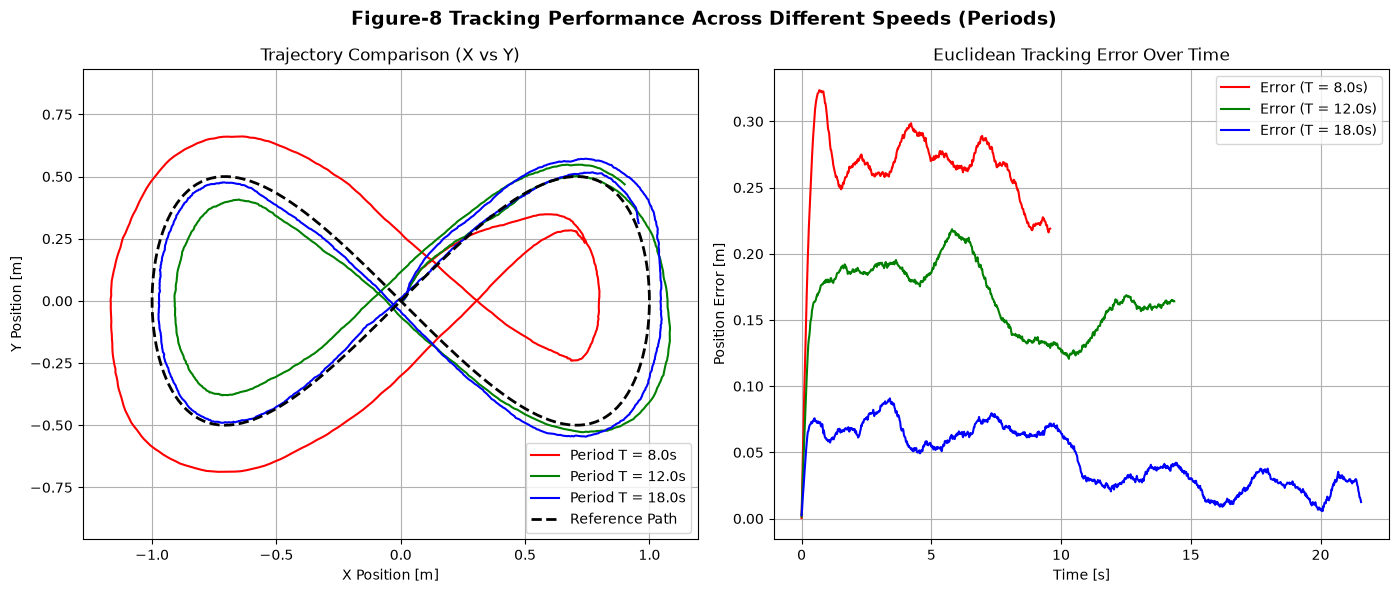

Speed comparison analysis completed successfully!


In [35]:
import numpy as np
import matplotlib.pyplot as plt
#from omniwheel_simulator import RobotParameters, OmniWheelSimulation
#from ControlSetup import PIDController, Figure8PathGenerator, compute_inverse_kinematics

def run_speed_comparison_simulation():
    """
    Compares figure-8 path tracking performance across different motion speeds 
    (controlled via path duration period T) under disturbed physical conditions.
    """
    dt = 0.02                    # 50 Hz control and simulation loop timestep
    periods = [8.0, 12.0, 18.0]  # Fast (8s), Medium (12s), Slow (18s) per full loop
    
    # Disturbed physics parameters to test robustness against slip and noise
    params_disturbed = RobotParameters(
        mass=2.7,
        inertia=0.0074,
        R_base=0.06,
        R=0.03,
        alpha_f=np.radians(30),
        alpha_b=np.radians(45),
        enable_disturbances=True,
        pose_noise_std=0.001,
        friction_noise_std=0.08
    )

    # Fixed PID gains for fair comparison across speeds
    kp = [3.5, 3.5, 2.0]
    ki = [0.1, 0.1, 0.05]
    kd = [0.4, 0.4, 0.2]
    output_limits = [2.0, 2.0, 3.0]

    results = {}

    for T in periods:
        print(f"Simulating Figure-8 Path with Period T = {T} seconds...")
        total_time = T * 1.2 # Run slightly past one full loop to observe settling
        num_steps = int(total_time / dt)
        
        path_gen = Figure8PathGenerator(amplitude=1.0, period=T)
        sim = OmniWheelSimulation(params_disturbed)
        controller = PIDController(kp, ki, kd, output_limits)
        
        states = [sim.state]
        ref_poses = []
        tracking_errors = []
        torques_logged = []

        for k in range(num_steps):
            t = k * dt
            ref_pose = path_gen.get_reference_pose(t)
            ref_poses.append(ref_pose)
            
            current_pose = sim.state.pose
            
            # 1. PID body velocity command
            body_vel_cmd = controller.compute(ref_pose, current_pose, dt)
            
            # 2. Inverse kinematics wheel mapping
            wheel_speed_cmds = compute_inverse_kinematics(
                body_vel_cmd, 
                params_disturbed.R_base, 
                params_disturbed.R, 
                params_disturbed.alpha_f, 
                params_disturbed.alpha_b
            )
            
            # 3. Physics step
            next_state, _ = sim.step(wheel_speed_cmds, dt)
            states.append(next_state)
            
            # Log metrics
            err = np.linalg.norm(next_state.pose[:2] - ref_pose[:2])
            tracking_errors.append(err)
            torques_logged.append(next_state.motor_torques)

        results[T] = {
            'states': states,
            'ref_poses': np.array(ref_poses),
            'errors': np.array(tracking_errors),
            'torques': np.array(torques_logged),
            'time': np.arange(len(tracking_errors)) * dt
        }

    # =========================================================================
    # Visualization: Comparing Speeds
    # =========================================================================
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle("Figure-8 Tracking Performance Across Different Speeds (Periods)", fontsize=14, fontweight='bold')

    colors = {8.0: 'r', 12.0: 'g', 18.0: 'b'}

    # Panel 1: Trajectory Tracking Comparison
    for T in periods:
        xy = np.array([s.pose[:2] for s in results[T]['states'][1:]])
        axs[0].plot(xy[:, 0], xy[:, 1], color=colors[T], linestyle='-', label=f'Period T = {T}s')
    
    # Plot reference shape once (using T=12 path generator)
    ref_plot = Figure8PathGenerator(amplitude=1.0, period=12.0)
    ref_path = np.array([ref_plot.get_reference_pose(t)[:2] for t in np.linspace(0, 12, 200)])
    axs[0].plot(ref_path[:, 0], ref_path[:, 1], 'k--', linewidth=2, label='Reference Path')
    
    axs[0].set_title("Trajectory Comparison (X vs Y)")
    axs[0].set_xlabel("X Position [m]")
    axs[0].set_ylabel("Y Position [m]")
    axs[0].grid(True)
    axs[0].legend()
    axs[0].axis('equal')

    # Panel 2: Tracking Error over Time
    for T in periods:
        res = results[T]
        axs[1].plot(res['time'], res['errors'], color=colors[T], label=f'Error (T = {T}s)')

    axs[1].set_title("Euclidean Tracking Error Over Time")
    axs[1].set_xlabel("Time [s]")
    axs[1].set_ylabel("Position Error [m]")
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()
    print("Speed comparison analysis completed successfully!")

if __name__ == "__main__":
    run_speed_comparison_simulation()